# Кейс 3. Прогноз отклика клиентов на банковский депозит (бинарная классификация)

Цель — построить модель, которая предсказывает, откроет ли клиент депозит. Модель оцениваем по PR-AUC и Lift: колл-центр должен звонить в первую очередь тем клиентам, у которых шанс согласия выше, чтобы конверсия росла, а операторы тратили меньше звонков впустую.

План работы:
1. Подготовка данных: удаляем дубликаты и признак, через который в модель утекает информация о результате звонка.
2. Новые признаки: строим их внутри пайплайна, чтобы кросс-валидация не давала завышенных оценок.
3. Обучение: сравниваем логистическую регрессию и градиентный бустинг. Обученные модели сохраняем на диск, чтобы не обучать их заново при каждом запуске.
4. Порог: подбираем порог классификации и разбираем результаты.
5. Интерпретация: смотрим через SHAP, какие признаки влияют на решение клиента.

In [19]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap 

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from catboost import CatBoostClassifier
from sklearn.metrics import (
    classification_report, roc_auc_score, average_precision_score,
    precision_recall_curve, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)

sns.set_theme(style='whitegrid', context='notebook')

# Загрузка данных и удаление полных дубликатов
df = pd.read_csv('bank-additional-full.csv', sep=';').drop_duplicates()
print(f"Размер датасета после очистки: {df.shape}")

Размер датасета после очистки: (41176, 21)


## 1. Подготовка признаков и разбиение на выборки

Главное на этом этапе — не допустить утечки данных.

Признак `duration` (длительность звонка) удаляем. До разговора его длительность неизвестна. С этим признаком метрики выходят почти идеальными, но на новых клиентах такая модель работать не будет.

Новые признаки (агрегаты, взаимодействия экономических показателей, обработку значения 999 в `pdays`) считаем внутри собственного класса `BankFeatureEngineer`. Тогда при кросс-валидации и поиске по сетке (GridSearch) агрегаты считаются только на обучающих фолдах, и данные проверочного фолда в них не попадают.

Оговорка: для логистической регрессии `BankFeatureEngineer` стоит внутри пайплайна, и это условие выполняется. Для CatBoost трансформер обучен один раз на всей обучающей выборке до `grid_search`, поэтому внутри кросс-валидации CatBoost агрегаты частично посчитаны и по проверочным фолдам. Агрегаты не используют целевую переменную, так что искажение здесь небольшое.

1.  **Предыдущие контакты и лояльность:**
*   `is_contacted_before`: Отмечает, был ли клиент уже в контакте до этой кампании.
*   `pdays_clean`: Сколько дней прошло с прошлого контакта. Значение "999", которое означало "не звонили раньше", заменили на "-1", чтобы алгоритм правильно понял, что звонков не было, а не что это было очень давно.
*   `has_previous_contacts`: Просто показывает, были ли раньше контакты с этим клиентом.
*   `contact_intensity`: Насколько активно контактировали с клиентом. Это отношение звонков в этой кампании к числу предыдущих контактов (звонков было / предыдущие контакты + 1). Это помогает понять, не беспокоят ли клиента слишком часто.

2.  **Макроэкономические показатели:**
*   `age_euribor_interaction`: Это произведение возраста клиента и ставки Euribor. Гипотеза: люди разного возраста по-разному реагируют на изменения доходности.
*   `real_rate_proxy`: Разница между ставкой Euribor и уровнем занятости. Это показывает, как соотносятся доходы по вкладам и общая экономическая ситуация.
*   `euribor_to_employed`: Отношение ставки Euribor к числу работающих. Еще один показатель того, в каком состоянии экономика была на момент звонка.

3.  **Агрегированные данные (профиль клиента и нагрузка на колл-центр):**
*   `job_cons_conf_mean`: Средний уровень доверия (consumer condidence) потребителей для профессии клиента. Это говорит о том, насколько уверены в своем будущем люди из той же социальной группы, что и клиент.
*   `month_freq`: Насколько загружен конкретный месяц звонками. Это помогает модели увидеть сезонные закономерности и понять, когда идет "массовый обзвон".

In [20]:
# Разделение на X и y до преобразований (защита от утечек)
X = df.drop(columns=['y', 'duration'])
y = (df['y'] == 'yes').astype(int)

categorical_features = X.select_dtypes(include=['object', 'category', 'string']).columns.tolist()

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

class BankFeatureEngineer(BaseEstimator, TransformerMixin):
    def __init__(self, drop_raw_pdays=False):
        self.drop_raw_pdays = drop_raw_pdays

    def fit(self, X, y=None):
        # Рассчитываем агрегации только на обучающем фолде
        self.global_conf_mean_ = X['cons.conf.idx'].mean()
        self.job_conf_mean_ = X.groupby('job', observed=False)['cons.conf.idx'].mean()
        self.month_freq_ = X['month'].value_counts(normalize=True)
        return self

    def transform(self, X):
        X = X.copy()
        # 1. История контактов
        X['is_contacted_before'] = (X['pdays'] != 999).astype(int)
        X['pdays_clean'] = np.where(X['pdays'] == 999, -1, X['pdays'])
        X['has_previous_contacts'] = (X['previous'] > 0).astype(int)
        X['contact_intensity'] = X['campaign'] / (X['previous'] + 1.0)

        # 2. Макроэкономика
        X['age_euribor_interaction'] = X['age'] * X['euribor3m']
        X['real_rate_proxy'] = X['euribor3m'] - X['emp.var.rate']
        X['euribor_to_employed'] = X['euribor3m'] / (X['nr.employed'] / 1000.0)

        # 3. Агрегации (с защитой от новых категорий через fillna)
        X['job_cons_conf_mean'] = X['job'].map(self.job_conf_mean_).astype(float).fillna(self.global_conf_mean_)
        X['month_freq'] = X['month'].map(self.month_freq_).astype(float).fillna(0.0)

        if self.drop_raw_pdays and 'pdays' in X.columns:
            X = X.drop(columns=['pdays'])

        for col in categorical_features:
            X[col] = X[col].astype('category')

        return X

## 2. Обучение и сохранение моделей

Сравниваем два подхода:
1. Базовая модель — логистическая регрессия. Она быстро обучается, и её коэффициенты легко объяснить.
2. CatBoost — градиентный бустинг, который работает с категориальными признаками без ручного кодирования.

Обученные модели и трансформер признаков сохраняются на диск. При перезапуске ядра ноутбук не обучает их заново, а загружает готовые файлы за доли секунды. Больше всего времени это экономит на бустинге.

In [21]:
# 1. BASELINE (Логистическая регрессия) 
if os.path.exists('baseline_lr_pipeline.pkl'):
    print("Загрузка сохраненной модели Baseline (Логистическая регрессия)...")
    best_lr_model = joblib.load('baseline_lr_pipeline.pkl')
else:
    print("Обучение модели Baseline...")
    sample_lr_df = BankFeatureEngineer(drop_raw_pdays=True).fit_transform(X_train_raw)
    numerical_features_lr = sample_lr_df.select_dtypes(exclude=['category']).columns.tolist()
    high_card_cats = ['job', 'education', 'month']

    cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

    preprocessor = ColumnTransformer(transformers=[
        ('num', StandardScaler(), numerical_features_lr),
        ('cat_ohe', OneHotEncoder(handle_unknown='ignore', drop='first'), categorical_features),
        ('cat_te', TargetEncoder(cv=3), high_card_cats)
    ])

    lr_pipeline = Pipeline(steps=[
        ('fe', BankFeatureEngineer(drop_raw_pdays=True)),
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(solver='saga', max_iter=1000, random_state=42))
    ])

    grid_search_lr = GridSearchCV(
        lr_pipeline, 
        param_grid={'classifier__C': [0.1, 1.0], 'classifier__class_weight': ['balanced']}, 
        cv=cv_strategy, scoring='average_precision', n_jobs=-1
    ).fit(X_train_raw, y_train)

    best_lr_model = grid_search_lr.best_estimator_
    joblib.dump(best_lr_model, 'baseline_lr_pipeline.pkl')
    print("Baseline обучен и сохранен.")

y_proba_lr = best_lr_model.predict_proba(X_test_raw)[:, 1]


# 2. CATBOOST 
if os.path.exists('catboost_tuned_model.cbm') and os.path.exists('catboost_feature_engineer.pkl'):
    print("Загрузка сохраненной модели CatBoost и трансформера...")
    fe_cb = joblib.load('catboost_feature_engineer.pkl')
    X_train_cb = fe_cb.transform(X_train_raw) 
    X_test_cb = fe_cb.transform(X_test_raw)
    
    cb_model = CatBoostClassifier()
    cb_model.load_model('catboost_tuned_model.cbm')
else:
    print("Обучение модели CatBoost...")
    fe_cb = BankFeatureEngineer(drop_raw_pdays=False)
    X_train_cb = fe_cb.fit_transform(X_train_raw)
    X_test_cb = fe_cb.transform(X_test_raw)

    cb_model = CatBoostClassifier(
        iterations=1000,
        cat_features=categorical_features,
        auto_class_weights='Balanced',
        eval_metric='PRAUC',
        early_stopping_rounds=50,
        random_seed=42
    )

    cb_model.grid_search(
    {
        'depth': [2, 4, 6], 
        'learning_rate': [0.03, 0.05, 0.1],
        'l2_leaf_reg': [5, 10, 20], 
        'random_strength': [1.0, 5.0, 10.0] 
    },
    X=X_train_cb, y=y_train, cv=3, verbose=False
)
    
    cb_model.save_model('catboost_tuned_model.cbm')
    joblib.dump(fe_cb, 'catboost_feature_engineer.pkl')
    print("CatBoost обучен и сохранен.")

y_proba_cb = cb_model.predict_proba(X_test_cb)[:, 1]

Загрузка сохраненной модели Baseline (Логистическая регрессия)...
Загрузка сохраненной модели CatBoost и трансформера...


## 3. Бизнес-метрики и визуализация результатов

Порог 0.5 по умолчанию редко бывает лучшим, особенно когда классы сильно несбалансированы: отказов в данных намного больше, чем согласий. Порог выбираем по максимуму F1, то есть ищем компромисс между полнотой и точностью. Полнота (Recall) — какую долю всех согласных клиентов модель находит. Точность (Precision) — какая доля тех, кому позвоним, согласится.

Порог подбираем на обучающей выборке, чтобы тестовая не участвовала в настройке. Но предсказания для подбора порога модель делает на тех же данных, на которых обучалась, а на них она увереннее, чем на новых клиентах. Порог поэтому может получиться завышенным. Надёжнее подбирать его по out-of-fold предсказаниям кросс-валидации.

Пользу модели для бизнеса измеряем через Lift@10%. Эта метрика показывает, во сколько раз конверсия среди 10% клиентов с самой высокой оценкой модели выше средней конверсии по всей базе, то есть выше, чем при случайном обзвоне.

,ROC-AUC,PR-AUC,Lift@10%
Модель,,,
Baseline (LogReg),0.8019,0.4455,4.3896
CatBoost,0.8076,0.4791,4.6656



Оптимальный порог CatBoost: 0.683

              precision    recall  f1-score   support

   Отказ (0)       0.94      0.93      0.94      9134
Согласие (1)       0.50      0.55      0.52      1160

    accuracy                           0.89     10294
   macro avg       0.72      0.74      0.73     10294
weighted avg       0.89      0.89      0.89     10294



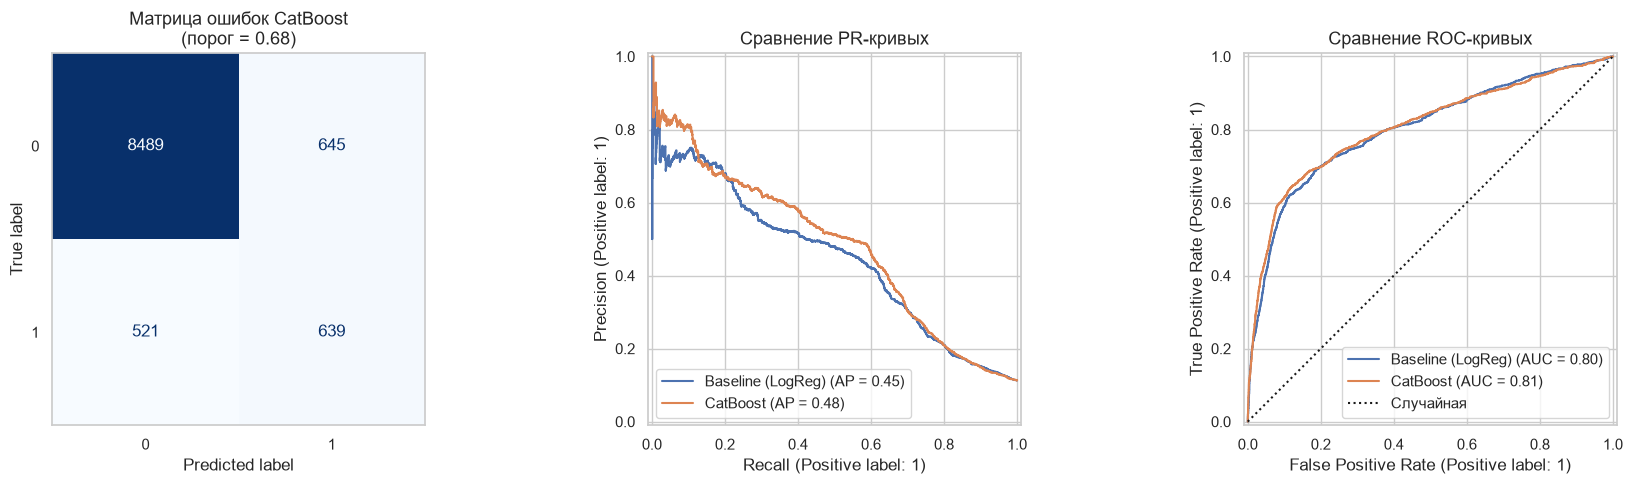

In [22]:
# Поиск оптимального порога на Train (избегаем утечек из Test)
train_proba_cb = cb_model.predict_proba(X_train_cb)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_train, train_proba_cb)
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-10)
optimal_threshold = thresholds[np.argmax(f1_scores)]

y_pred_cb_optimal = (y_proba_cb >= optimal_threshold).astype(int)

# Расчет метрики Lift
def calculate_lift(y_true, y_proba, top_pct=0.1):
    df_lift = pd.DataFrame({'true': y_true, 'proba': y_proba}).sort_values(by='proba', ascending=False)
    top_n = max(1, int(len(df_lift) * top_pct))
    return df_lift.head(top_n)['true'].mean() / y_true.mean()

# Сравнение моделей
metrics_df = pd.DataFrame([
    {'Модель': 'Baseline (LogReg)', 'ROC-AUC': roc_auc_score(y_test, y_proba_lr), 'PR-AUC': average_precision_score(y_test, y_proba_lr), 'Lift@10%': calculate_lift(y_test, y_proba_lr)},
    {'Модель': 'CatBoost', 'ROC-AUC': roc_auc_score(y_test, y_proba_cb), 'PR-AUC': average_precision_score(y_test, y_proba_cb), 'Lift@10%': calculate_lift(y_test, y_proba_cb)}
]).set_index('Модель')

display(metrics_df.round(4))
print(f"\nОптимальный порог CatBoost: {optimal_threshold:.3f}\n")
print(classification_report(y_test, y_pred_cb_optimal, target_names=["Отказ (0)", "Согласие (1)"]))

# Визуализация 
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_cb_optimal, cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title(f"Матрица ошибок CatBoost\n(порог = {optimal_threshold:.2f})", fontsize=13)
axes[0].grid(False)

for y_prob, name in [(y_proba_lr, 'Baseline (LogReg)'), (y_proba_cb, 'CatBoost')]:
    PrecisionRecallDisplay.from_predictions(y_test, y_prob, ax=axes[1], name=name)
    RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[2], name=name)

axes[1].set_title("Сравнение PR-кривых", fontsize=13)
axes[2].plot([0, 1], [0, 1], 'k:', label='Случайная')
axes[2].legend(loc='lower right')
axes[2].set_title("Сравнение ROC-кривых", fontsize=13)
plt.tight_layout()
plt.show()

## 4. Интерпретация модели с помощью SHAP

Маркетологам нужно понимать, почему модель советует звонить одним клиентам и не звонить другим. Для этого используем библиотеку SHAP (SHapley Additive exPlanations) и смотрим, из чего складываются предсказания CatBoost.

Строим два графика:
1. Bar plot — глобальная важность признаков, то есть средний по модулю вклад каждого признака в предсказание.
2. Summary plot — направление влияния: как высокое или низкое значение признака сдвигает вероятность согласия.

Глобальная важность признаков (Bar Plot):


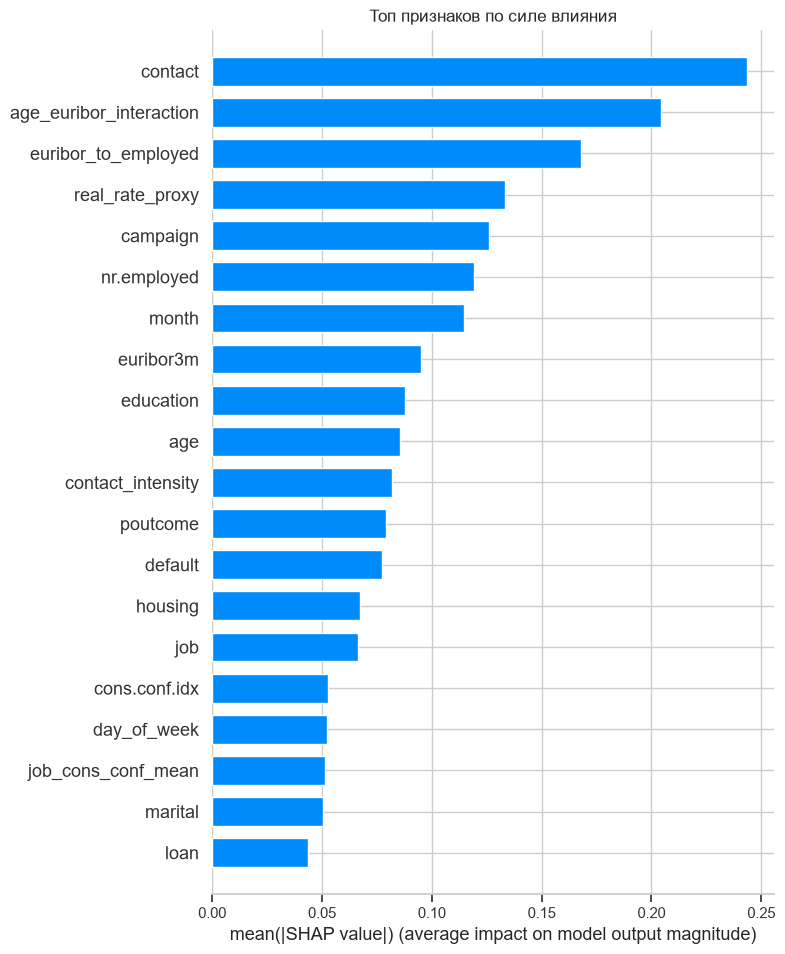

Влияние признаков на конкретные предсказания (Summary Plot):


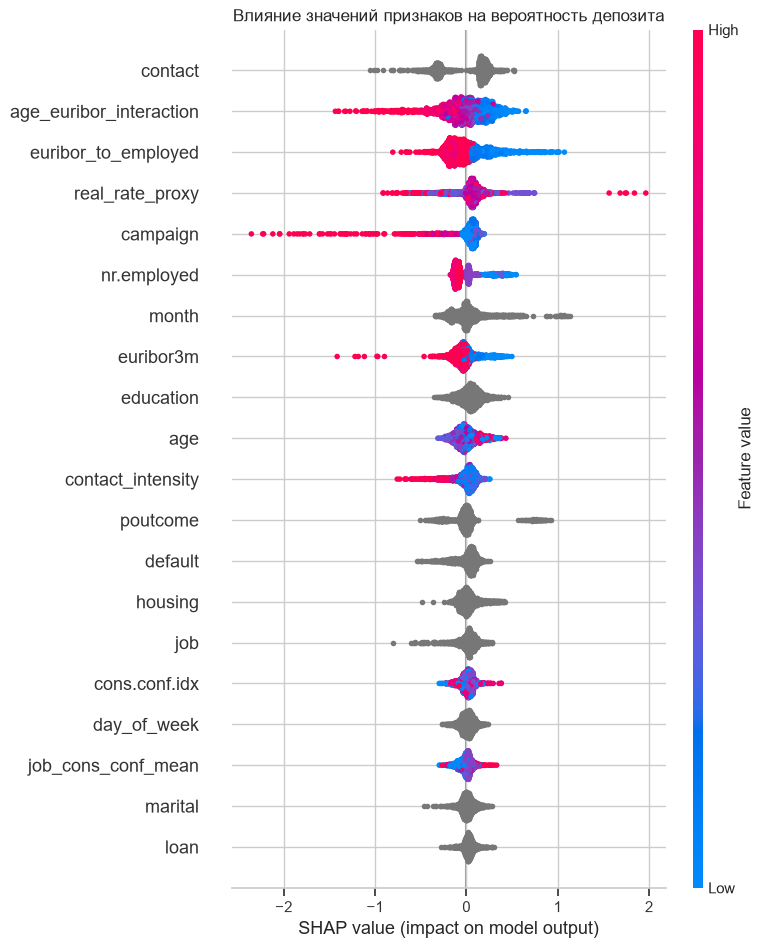

In [23]:
# Инициализируем TreeExplainer для обученного CatBoost
explainer = shap.TreeExplainer(cb_model)

# Для ускорения расчетов берем случайную подвыборку из тестового сета (например, 2000 строк)
X_test_sample = X_test_cb.sample(n=min(2000, len(X_test_cb)), random_state=42)
shap_values = explainer.shap_values(X_test_sample)

plt.figure(figsize=(10, 6))
print("Глобальная важность признаков (Bar Plot):")
shap.summary_plot(shap_values, X_test_sample, plot_type="bar", show=False)
plt.title("Топ признаков по силе влияния")
plt.show()

plt.figure(figsize=(10, 6))
print("Влияние признаков на конкретные предсказания (Summary Plot):")
shap.summary_plot(shap_values, X_test_sample, show=False)
plt.title("Влияние значений признаков на вероятность депозита")
plt.show()

Анализ конверсии по каналам связи:


,contact,clients_count,conversion_%
0,cellular,19652,14.72
1,telephone,11230,5.23


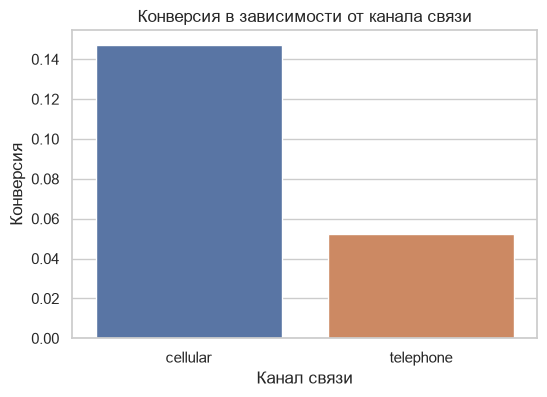

In [24]:
# Объединим признаки и целевую переменную обучающей выборки
df_train = X_train_raw.copy()
df_train['target'] = y_train

# Считаем конверсию (среднее значение target) и объем базы по каждому каналу
conversion_by_contact = df_train.groupby('contact').agg(
    conversion=('target', 'mean'),
    clients_count=('target', 'count')
).reset_index()

# Округлим конверсию для красоты отображения (в процентах)
conversion_by_contact['conversion_%'] = (conversion_by_contact['conversion'] * 100).round(2)

print("Анализ конверсии по каналам связи:")
display(conversion_by_contact[['contact', 'clients_count', 'conversion_%']])

# Визуализация
plt.figure(figsize=(6, 4))
sns.barplot(data=conversion_by_contact, x='contact', y='conversion', hue='contact')
plt.title('Конверсия в зависимости от канала связи')
plt.ylabel('Конверсия')
plt.xlabel('Канал связи')
plt.show()

## 5. Выводы

1. На тестовой выборке CatBoost лучше логистической регрессии по всем трём метрикам: ROC-AUC 0.8076 против 0.8019, PR-AUC 0.4791 против 0.4455, Lift@10% 4.66 против 4.39. Разница небольшая и проверена на одном разбиении. Чтобы говорить об устойчивом превосходстве, нужно сравнить модели на кросс-валидации или на нескольких случайных разбиениях. Вероятно, бустинг выигрывает за счёт нелинейных зависимостей, которые логистическая регрессия без ручных взаимодействий не видит.
2. Признак `duration` удалён, поэтому ROC-AUC — это качество модели в тот момент, когда маркетолог ещё только решает, кому звонить.
3. Конверсия среди 10% клиентов с самой высокой оценкой модели в 4.7 раза выше средней конверсии по базе. Если звонить только им, операторы тратят меньше звонков на отказы. Экономию в деньгах не считали: для этого нужны стоимость звонка и доход банка с одного депозита.
4. Порог, подобранный по F1, равен 0.683. На тестовой выборке при этом пороге precision равна 0.50, recall — 0.55: согласится примерно каждый второй из тех, кому позвоним, и модель находит примерно половину всех согласных клиентов. Порог можно двигать: снижать, чтобы найти больше согласных ценой большего числа звонков, или повышать, чтобы звонить меньше и точнее.
5. Что показал SHAP.

   Самый сильный признак — канал связи `contact`. Признак категориальный, поэтому направление влияния на summary plot не видно; его стоит проверить отдельно, например сравнив конверсию по каналам.

   Следом идут макроэкономические признаки: `nr.employed`, `age_euribor_interaction`, `euribor_to_employed`, `emp.var.rate`, `euribor3m`. У всех них низкие значения повышают вероятность согласия, высокие снижают. Клиенты чаще открывают депозит при низкой ставке Euribor и низкой занятости. У `real_rate_proxy` высокие значения в основном тоже снижают вероятность, хотя у нескольких клиентов с очень высокими значениями вклад сильно положительный.

   На третьем месте `month_freq`: в месяцы, когда банк звонил мало, доля согласий выше. Скорее всего, это эффект объёма кампании, а сезонность здесь играет меньшую роль: сам признак `month` стоит только на 16-м месте.

   `campaign` и `contact_intensity` показывают, что клиенты, которым в текущей кампании звонили много раз, соглашаются реже. Причинность отсюда не следует, но многократный обзвон одного клиента выглядит малоэффективным.

   У части клиентов `poutcome` даёт большой положительный вклад. Вероятно, это клиенты, у которых прошлая кампания закончилась успехом, но по графику категории не различить. Признаки самого факта прошлого контакта (`is_contacted_before`, `has_previous_contacts`, `pdays_clean`) в двадцатку важных не вошли.